In [ ]:
import numpy as np
import pandas as pd

URL = "https://raw.githubusercontent.com/RoMarlene/TPI---Introduccion-al-analisis-de-datos---Comision-143-C2/main/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(URL)
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [ ]:
URL = "https://raw.githubusercontent.com/RoMarlene/TPI---Introduccion-al-analisis-de-datos---Comision-143-C2/64e3442c326a6edd0aad586eb4647571693f6c92/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(URL)
dfCopia = df.copy()

pd.DataFrame(dfCopia)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [ ]:
df[
    [
        "PaymentMethod",
        "Churn",

    ]
].value_counts()


,,count
PaymentMethod,Churn,
Mailed check,No,1304
Electronic check,No,1294
Credit card (automatic),No,1290
Bank transfer (automatic),No,1286
Electronic check,Yes,1071
Mailed check,Yes,308
Bank transfer (automatic),Yes,258
Credit card (automatic),Yes,232


In [ ]:
df["cancelo"] = df["Churn"] == "Yes"      # True si canceló, False si no

tabla = df.groupby("PaymentMethod")["cancelo"].agg(["count", "sum", "mean"])
#print(tabla["mean"])
#print("====================")
tabla["mean"] = (tabla["mean"] * 100).round(2)
#print(tabla["mean"])
tabla = tabla.rename(columns={
    "count": "total",
    "sum": "cancelados",
    "mean": "tasa_churn_%",
})

tabla.sort_values("tasa_churn_%", ascending=False)

,total,cancelados,tasa_churn_%
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24


In [ ]:
df["cancelo"] = df["Churn"] == "Yes"

clientes_menos_13 = df[df["tenure"] < 13]
clientes_mas_13 = df[df["tenure"] >= 13]

tabla = pd.DataFrame({
    "antiguedad": ["Menos de 13 meses", "13 meses o más"],
    "total": [
        clientes_menos_13["cancelo"].count(),
        clientes_mas_13["cancelo"].count()
    ],
    "cancelados": [
        clientes_menos_13["cancelo"].sum(),
        clientes_mas_13["cancelo"].sum()
    ],
    "tasa churn%": [
        (clientes_menos_13["cancelo"].mean() * 100).round(2),
        (clientes_mas_13["cancelo"].mean() * 100).round(2)
    ]
})

display(tabla)

,antiguedad,total,cancelados,tasa churn%
0,Menos de 13 meses,2186,1037,47.44
1,13 meses o más,4857,832,17.13


In [ ]:
dfCopia[dfCopia["TotalCharges"].str.strip() == ""]


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [ ]:
valoresBlanco = (dfCopia["TotalCharges"].str.strip() == "").sum()
print("Valores en blanco del dataset: ", valoresBlanco)

Valores en blanco del dataset:  11


In [ ]:
valoresBlanco = (dfCopia["TotalCharges"].str.strip() == "").sum()
print("Valores en blanco del dataset: ", valoresBlanco)

Valores en blanco del dataset:  11


In [ ]:
dfCopia["TotalCharges"] = pd.to_numeric(dfCopia["TotalCharges"], errors="coerce")
#Convierte en numero la columna TotalCharges

In [ ]:
dfCopia["TotalCharges"].isnull().sum()
#Confirmamos que son 11 ahora los valores Nan

np.int64(11)

In [ ]:
tabla = dfCopia.loc[
    df["Churn"] == "Yes",
    ["customerID", "MonthlyCharges", "TotalCharges"]
]

display(tabla)

comparacion = dfCopia.groupby("Churn").agg(
    cantidad_clientes=("customerID", "count"), #cuenta cuantos clientes hay en cada grupo
    promedio_mensual=("MonthlyCharges", "mean"), #calcula el promedio de cuanto pagan MENSUALMENTE los clientes de cada grupo
    promedio_total=("TotalCharges", "mean") #calcula el promedio de cuanto pagan en TOTAL los clientes de cada grupo
)

display(comparacion)

,customerID,MonthlyCharges,TotalCharges
2,3668-QPYBK,53.85,108.15
4,9237-HQITU,70.70,151.65
5,9305-CDSKC,99.65,820.50
8,7892-POOKP,104.80,3046.05
13,0280-XJGEX,103.70,5036.30
...,...,...,...
7021,1699-HPSBG,59.80,727.80
7026,8775-CEBBJ,44.20,403.35
7032,6894-LFHLY,75.75,75.75
7034,0639-TSIQW,102.95,6886.25


,cantidad_clientes,promedio_mensual,promedio_total
Churn,,,
No,5174,61.265124,2555.344141
Yes,1869,74.441332,1531.796094


In [ ]:
print("Filas y columnas:", dfCopia.shape)


dfCopia.info()                     # tipos y nulos
print("Valores nulos:", dfCopia.isnull().sum())

Filas y columnas: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBill

In [ ]:
print("------Duplicados ---")
dfCopia[dfCopia.duplicated()]

------Duplicados ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [ ]:
dfCopia.duplicated().sum()


np.int64(0)

In [ ]:
dfCopia[dfCopia["customerID"].duplicated()].sum()


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
print("ID duplicados: ", dfCopia["customerID"].duplicated().sum())


ID duplicados:  0


In [ ]:
dfCopia["TotalCharges"].dtype


dtype('float64')

In [ ]:
dfCopia[dfCopia["TotalCharges"].isnull()]
dfCopia.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
dfCopia[dfCopia["TotalCharges"].isnull()]["tenure"]


,tenure
488,0
753,0
936,0
1082,0
1340,0
3331,0
3826,0
4380,0
5218,0
6670,0


In [ ]:
dfCopia["SeniorCitizen"] = dfCopia["SeniorCitizen"].replace({0: "No", 1: "Yes"})
dfCopia["SeniorCitizen"].value_counts()
#Reemplacé valores numéricos a variables categóricas

,count
SeniorCitizen,
No,5901
Yes,1142


In [ ]:
dfCopia.dtypes


,0
customerID,object
gender,object
SeniorCitizen,object
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [ ]:
dfCopia.drop(columns=["customerID"], inplace=True)
dfCopia.columns


Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
columnas = ["tenure", "MonthlyCharges", "TotalCharges"]
q1 = dfCopia[columnas].quantile(0.25)
q3 = dfCopia[columnas].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr


In [ ]:
outliers = (dfCopia[columnas] < limite_inferior) | (dfCopia[columnas] > limite_superior)
outliers.sum()


,0
tenure,0
MonthlyCharges,0
TotalCharges,0


,0
tenure,"Axes(0.125,0.11;0.227941x0.77)"
MonthlyCharges,"Axes(0.398529,0.11;0.227941x0.77)"
TotalCharges,"Axes(0.672059,0.11;0.227941x0.77)"


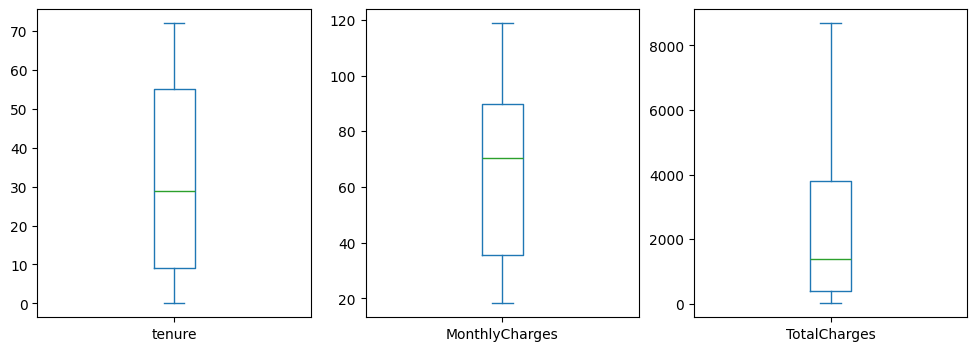

In [ ]:
dfCopia[columnas].plot(kind="box", subplots=True, figsize=(12, 4))


In [ ]:
dfCopia.to_csv("telco_churn_limpio.csv", index=False)
#from google.colab import files
#files.download("telco_churn_limpio.csv")



In [ ]:
dfCopia[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2)


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


In [ ]:
dfCopia[["tenure", "MonthlyCharges", "TotalCharges"]].mode()

,tenure,MonthlyCharges,TotalCharges
0,1,20.05,20.2


In [ ]:
dfCopia[["tenure", "MonthlyCharges", "TotalCharges"]].var().round(2)

,0
tenure,603.17
MonthlyCharges,905.41
TotalCharges,5138252.41


In [ ]:
q1 = dfCopia[["tenure", "MonthlyCharges", "TotalCharges"]].quantile(0.25)
q3 =  dfCopia[["tenure", "MonthlyCharges", "TotalCharges"]].quantile(0.75)
iqr = q3 - q1
display(iqr)

,0
tenure,46.0000
MonthlyCharges,54.3500
TotalCharges,3393.2875


In [ ]:
print("Rango (máximo - mínimo) de cada variable:")
dfCopia[["tenure", "MonthlyCharges", "TotalCharges"]].max() - dfCopia[["tenure", "MonthlyCharges", "TotalCharges"]].min()

Rango (máximo - mínimo) de cada variable:


,0
tenure,72.0
MonthlyCharges,100.5
TotalCharges,8666.0


In [ ]:
#columnas = ["tenure", "MonthlyCharges", "TotalCharges"]

# Matriz de correlación de Pearson
# (corr() ignora automáticamente las filas con NaN, par por par)
dfCopia[columnas].corr(method="pearson").round(2)

,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


In [ ]:
#Variables sociodemográficas
variables_sociodemograficas = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

#Variables relacionadas con la contratación
variables_contratacion = [
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

In [ ]:
print(" FRECUENCIAS ABSOLUTAS - SOCIODEMOGRÁFICAS ")

for variable in variables_sociodemograficas:
    print(f"\nFrecuencia absoluta de {variable}:")
    tbl_absoluta_1 = df[variable].value_counts()
    display(tbl_absoluta_1)

print("------------------------------------------------")

print(" FRECUENCIAS ABSOLUTAS - CONTRATACIÓN ")
for variable in variables_contratacion:
    print(f"\nFrecuencia absoluta de {variable}:")
    tbl_absoluta_2 = df[variable].value_counts()
    display(tbl_absoluta_2)

 FRECUENCIAS ABSOLUTAS - SOCIODEMOGRÁFICAS 

Frecuencia absoluta de gender:


,count
gender,
Male,3555
Female,3488



Frecuencia absoluta de SeniorCitizen:


,count
SeniorCitizen,
0,5901
1,1142



Frecuencia absoluta de Partner:


,count
Partner,
No,3641
Yes,3402


... (22 outputs left out)


Frecuencia absoluta de PaperlessBilling:


,count
PaperlessBilling,
Yes,4171
No,2872



Frecuencia absoluta de PaymentMethod:


,count
PaymentMethod,
Electronic check,2365
Mailed check,1612
Bank transfer (automatic),1544
Credit card (automatic),1522


In [ ]:
print(" FRECUENCIAS RELATIVAS - SOCIODEMOGRÁFICAS ")

for variable in variables_sociodemograficas:
    print(f"\nFrecuencia relativa de {variable}:")
    tbl_relativa_1 = df[variable].value_counts(normalize=True) * 100
    display(
        tbl_relativa_1.round(2)
        .to_frame() # Convierte Series object en un df de una sola columna
        .style.format("{:.2f}%"))

print("------------------------------------------------")

print(" FRECUENCIAS RELATIVAS - CONTRATACIÓN ")
for variable in variables_contratacion:
    print(f"\nFrecuencia relativa de {variable}:")
    tbl_relativa_2 = df[variable].value_counts(normalize=True) * 100
    display(
        tbl_relativa_2
        .round(2)
        .to_frame()
        .style.format("{:.2f}%"))


 FRECUENCIAS RELATIVAS - SOCIODEMOGRÁFICAS 

Frecuencia relativa de gender:


,proportion
gender,
Male,50.48%
Female,49.52%



Frecuencia relativa de SeniorCitizen:


,proportion
SeniorCitizen,
0,83.79%
1,16.21%



Frecuencia relativa de Partner:


,proportion
Partner,
No,51.70%
Yes,48.30%


... (22 outputs left out)


Frecuencia relativa de PaperlessBilling:


,proportion
PaperlessBilling,
Yes,59.22%
No,40.78%



Frecuencia relativa de PaymentMethod:


,proportion
PaymentMethod,
Electronic check,33.58%
Mailed check,22.89%
Bank transfer (automatic),21.92%
Credit card (automatic),21.61%


In [ ]:
print(" TABLAS DE CONTINGENCIA CON FRECUENCIAS ABSOLUTAS Y RELATIVAS - SOCIODEMOGRÁFICAS ")

for variable in variables_sociodemograficas:

    print(f"\nTabla de contingencia: {variable} vs Churn")

    # Frecuencias absolutas
    print("\nFrecuencias absolutas:")
    tabla_absoluta = pd.crosstab(df[variable], df["Churn"])
    display(tabla_absoluta)


    # Frecuencias relativas
    print("\nFrecuencias relativas:")
    tabla_relativa = pd.crosstab(df[variable], df["Churn"], normalize="index") * 100
    display(tabla_relativa.round(2).style.format("{:.2f}%"))


    print("-----------------------------------------------")


 TABLAS DE CONTINGENCIA CON FRECUENCIAS ABSOLUTAS Y RELATIVAS - SOCIODEMOGRÁFICAS 

Tabla de contingencia: gender vs Churn

Frecuencias absolutas:


Churn,No,Yes
gender,,
Female,2549,939
Male,2625,930



Frecuencias relativas:


Churn,No,Yes
gender,,
Female,73.08%,26.92%
Male,73.84%,26.16%


-----------------------------------------------

Tabla de contingencia: SeniorCitizen vs Churn

Frecuencias absolutas:


Churn,No,Yes
SeniorCitizen,,
0,4508,1393
1,666,476


... (7 outputs left out)

Churn,No,Yes
Dependents,,
No,3390,1543
Yes,1784,326



Frecuencias relativas:


Churn,No,Yes
Dependents,,
No,68.72%,31.28%
Yes,84.55%,15.45%


-----------------------------------------------


In [ ]:
print(" TABLAS DE CONTINGENCIA CON FRECUENCIAS ABSOLUTAS Y RELATIVAS - CONTRATACIÓN ")

for variable in variables_contratacion:

    print(f"\nTabla de contingencia: {variable} vs Churn")

    # Frecuencias absolutas
    print("\nFrecuencias absolutas:")
    tabla_absoluta = pd.crosstab(df[variable], df["Churn"])
    display(tabla_absoluta)


    # Frecuencias relativas
    print("\nFrecuencias relativas:")
    tabla_relativa = pd.crosstab(df[variable], df["Churn"], normalize="index") * 100
    display(tabla_relativa.round(2).style.format("{:.2f}%"))

    print("-----------------------------------------------")

 TABLAS DE CONTINGENCIA CON FRECUENCIAS ABSOLUTAS Y RELATIVAS - CONTRATACIÓN 

Tabla de contingencia: PhoneService vs Churn

Frecuencias absolutas:


Churn,No,Yes
PhoneService,,
No,512,170
Yes,4662,1699



Frecuencias relativas:


Churn,No,Yes
PhoneService,,
No,75.07%,24.93%
Yes,73.29%,26.71%


-----------------------------------------------

Tabla de contingencia: MultipleLines vs Churn

Frecuencias absolutas:


Churn,No,Yes
MultipleLines,,
No,2541,849
No phone service,512,170
Yes,2121,850


... (39 outputs left out)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308



Frecuencias relativas:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29%,16.71%
Credit card (automatic),84.76%,15.24%
Electronic check,54.71%,45.29%
Mailed check,80.89%,19.11%


-----------------------------------------------


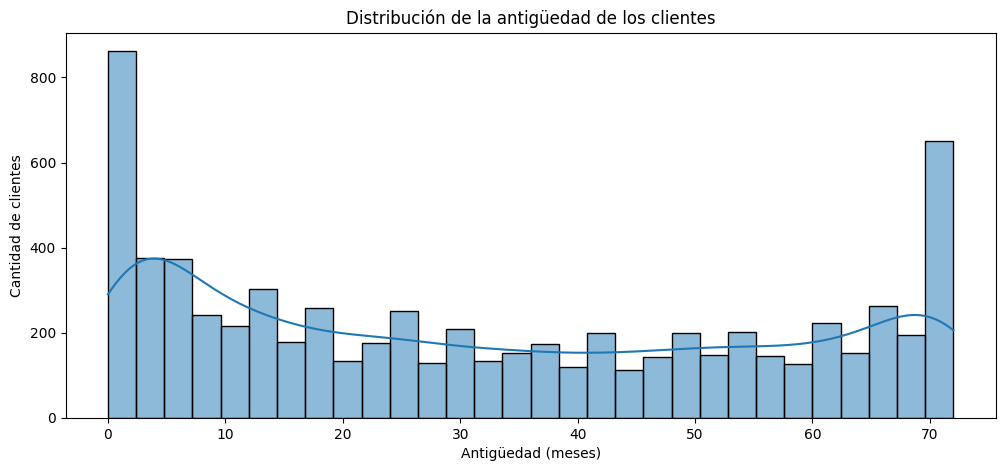

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

#Configurar el tamaño de los gráficos
plt.figure(figsize=(12, 5))

#Histograma y KDE de tenure
sns.histplot(
    data=df,
    x="tenure",
    kde=True, # Agrega la curva de densidad KDE
    bins=30 # definimos la cantidad de intervalos (barras) del gráfico
)

plt.title("Distribución de la antigüedad de los clientes")
plt.xlabel("Antigüedad (meses)")
plt.ylabel("Cantidad de clientes")
plt.show()

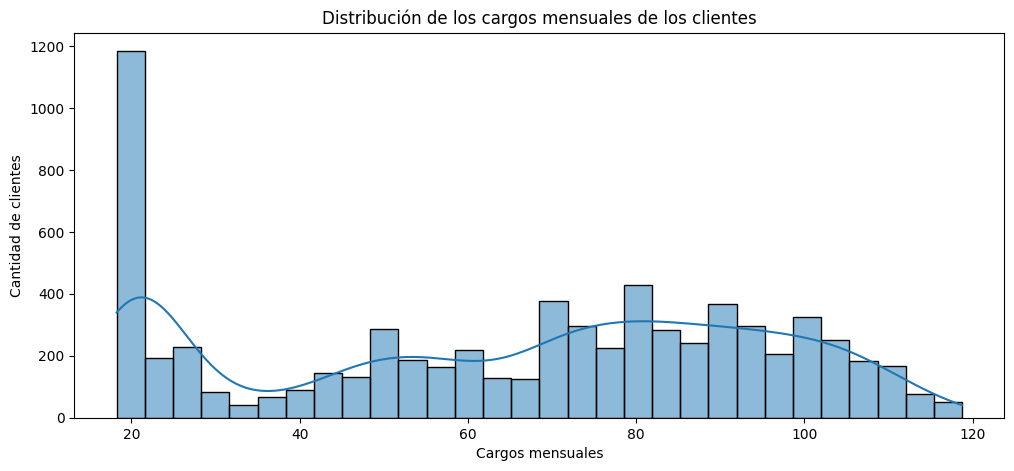

In [ ]:
# Histograma y KDE de MonthlyCharges
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    kde=True,
    bins=30
)

plt.title("Distribución de los cargos mensuales de los clientes")
plt.xlabel("Cargos mensuales")
plt.ylabel("Cantidad de clientes")
plt.show()

                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00


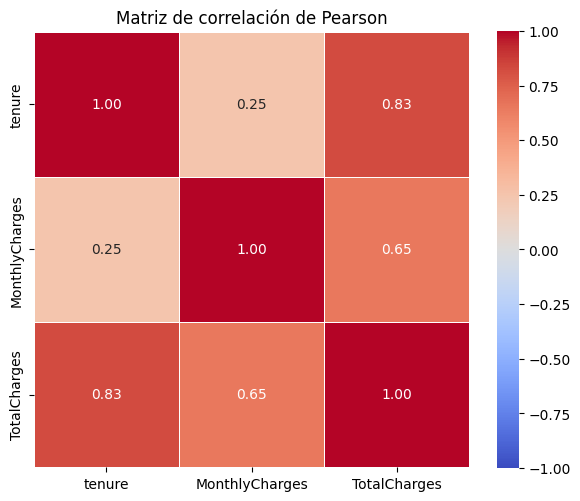

In [ ]:
#columnas, ya instanciada antes = ["tenure", "MonthlyCharges", "TotalCharges"]

# 2. Matriz de correlación de Pearson
corr = dfCopia[columnas].corr(method="pearson")
print(corr.round(2))

# 3. Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Matriz de correlación de Pearson")
plt.tight_layout()
plt.show()

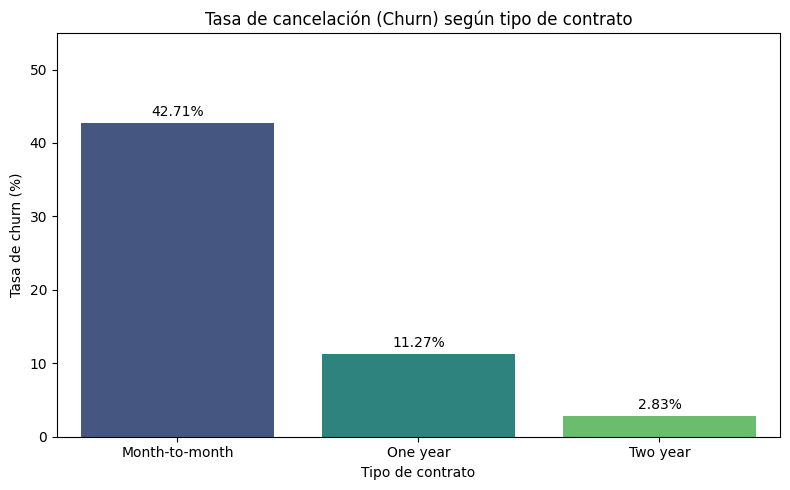

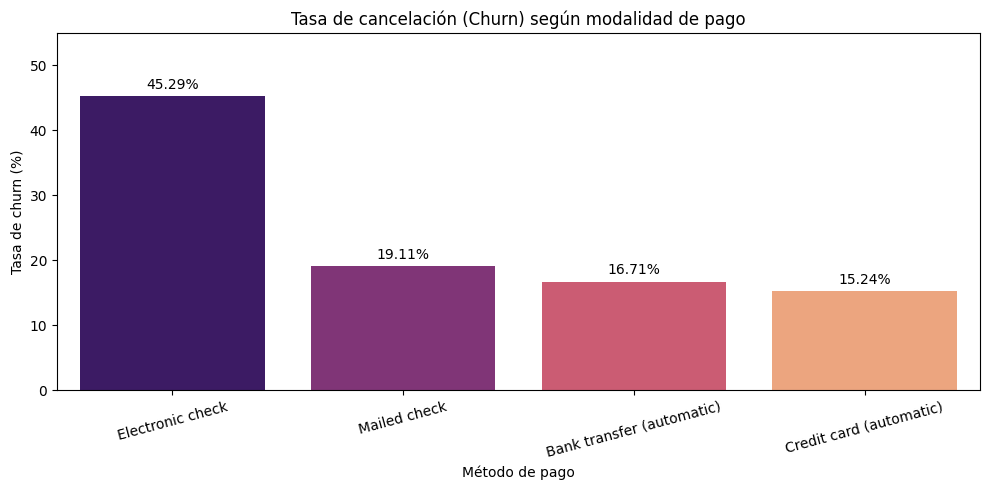

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Columna numérica de churn (1 = canceló, 0 = no)
df["cancelo"] = (df["Churn"] == "Yes").astype(int)

# ---------- Gráfico 1: Churn por tipo de contrato ----------
churn_contrato = (
    df.groupby("Contract")["cancelo"].mean() * 100
).sort_values(ascending=False).reset_index()
churn_contrato.columns = ["Contract", "tasa_churn"]

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=churn_contrato, x="Contract", y="tasa_churn",
                 hue="Contract", palette="viridis", legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)
plt.title("Tasa de cancelación (Churn) según tipo de contrato")
plt.xlabel("Tipo de contrato")
plt.ylabel("Tasa de churn (%)")
plt.ylim(0, 55)
plt.tight_layout()
plt.show()

# ---------- Gráfico 2: Churn por modalidad de pago ----------
churn_pago = (
    df.groupby("PaymentMethod")["cancelo"].mean() * 100
).sort_values(ascending=False).reset_index()
churn_pago.columns = ["PaymentMethod", "tasa_churn"]

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=churn_pago, x="PaymentMethod", y="tasa_churn",
                 hue="PaymentMethod", palette="magma", legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)
plt.title("Tasa de cancelación (Churn) según modalidad de pago")
plt.xlabel("Método de pago")
plt.ylabel("Tasa de churn (%)")
plt.ylim(0, 55)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()